partimos por configurar estas preguntas *Escribe aquí tu plan de trabajo inicial. Aborda brevemente:*
1. *¿Cómo planeas unir los datos y qué harás con los valores nulos generados?*
3. *¿Cuál será tu variable objetivo y qué tipo de problema de Machine Learning resolverás?*
4. *¿Qué pasos de preprocesamiento (codificación categórica, fechas, etc.) consideras necesarios y sobre que variables?*
5. *¿Qué modelos planeas entrenar?*

1.**Unión de datos y nulos.** Mi plan de trabajo es unir las tablas por la columna customerID, se resguardaran los datos de la tabla "Contract" para no perder los datos de quien no tiene internet ni telefono.los datos que tengan un Nan no se rellenaran porque significa que no contrataron ese servicio.los nulos de totalcharges se revisaran paso a paso.

2.**Variable objetivo y tipo de problema.** mi variable objetivo sera sera si tiene "EndDate" si tiene sera fecha de baja osea churn=1 pero si sigue activo sera churn=0, de sa forma hacemos el problema de clasificacion binaria.

3. **Preprocesamiento.**
   - Fechas: convertir `BeginDate` y `EndDate` a fecha y derivar una antigüedad en días. Se evaluará el riesgo de **fuga de datos**, porque la antigüedad de quien ya se fue se mide hasta su baja.
   - Categóricas binarias y multicategoría: *one-hot encoding* (no hay orden natural entre categorías). En regresión logística se usa `drop="first"` para evitar colinealidad.
   - Numéricas (`MonthlyCharges`, `TotalCharges`): escaladas solo para la regresión logística.
   - Se descartan `customerID`, `EndDate` y `BeginDate` como variables explicativas.

4. **Modelos.** *Baseline* sin balanceo: Regresión Logística y Random Forest. Luego, modelo optimizado: LightGBM con pesos de clase, búsqueda aleatoria de hiperparámetros con validación cruzada (optimizando AUC-ROC) y ajuste del umbral de decisión para priorizar Recall.

*El plan evolucionó durante el análisis: se detectó fuga de datos en la duración del contrato y se documentó en la sección 4.*

### |1. Exploración de Datos (EDA)
*Carga de datos, análisis de distribuciones, identificación de anomalías.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, recall_score, precision_score,
                             confusion_matrix, roc_curve)
# Semilla para reproducibilidad
RANDOM_STATE = 12345
np.random.seed(RANDOM_STATE)

In [2]:
archivo_contract = '/datasets/final_provider/contract.csv'
archivo_personal = '/datasets/final_provider/personal.csv'
archivo_internet = '/datasets/final_provider/internet.csv'
archivo_phone = '/datasets/final_provider/phone.csv'

In [3]:
df_contract = pd.read_csv(archivo_contract)
df_personal = pd.read_csv(archivo_personal)
df_internet = pd.read_csv(archivo_internet)
df_phone = pd.read_csv(archivo_phone)

In [4]:
df_contract.info()
df_contract.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [5]:
df_contract.isna().sum()

customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

In [6]:
df_personal.info()
df_personal.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


In [7]:
df_personal.isna().sum()

customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

In [8]:
df_internet.info()
df_internet.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


In [9]:
df_internet.isna().sum()

customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

In [10]:
df_phone.info()
df_phone.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [11]:
df_phone.isna().sum()

customerID       0
MultipleLines    0
dtype: int64

**Lectura de la carga de datos**
- `contract` y `personal` tienen 7.043 clientes; `internet` tiene 5.517 y `phone` 6.361. Los clientes que faltan en esas dos tablas no contrataron ese servicio, así que los nulos que aparezcan al unir no son datos perdidos.
- Ninguna tabla tiene nulos propios.
- `TotalCharges` llega como texto (`object`) y `EndDate` mezcla fechas con el texto `"No"`. Ambos se corrigen en la sección siguiente.

### 2. Preprocesamiento e Ingeniería de Características
*Procesar valores nulos, creación de la variable objetivo, codificación de variables categóricas (justifica tu elección de método).*
*Pista: Los modelos predictivos no entienden de fechas en formato texto. ¿Cómo puedes transformar las fechas de inicio y fin en una variable numérica útil para el modelo?*

In [12]:
df_contract["TotalCharges"] = pd.to_numeric(df_contract["TotalCharges"], errors="coerce")
df_contract.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7032 non-null   float64
dtypes: float64(2), object(6)
memory usage: 440.3+ KB


In [13]:
# 1. Variable objetivo (antes de tocar EndDate)
df_contract["Churn"] = (df_contract["EndDate"] != "No").astype(int)

# 2. Convertir a fecha (errors="coerce" convierte "No" en NaT)
df_contract["BeginDate"] = pd.to_datetime(df_contract["BeginDate"])
df_contract["EndDate"] = pd.to_datetime(df_contract["EndDate"], errors="coerce")

# 3. Fecha de referencia para los clientes activos
fecha_ref = df_contract["BeginDate"].max()   # o la fecha de corte que indique el enunciado

# 4. Duración en días (numérica, apta para el modelo)
df_contract["DuracionDias"] = (df_contract["EndDate"].fillna(fecha_ref) - df_contract["BeginDate"]).dt.days

**Variable objetivo y duración**
- `Churn` = 1 si `EndDate` tiene fecha y 0 si el cliente sigue activo. Se crea **antes** de convertir `EndDate`, porque al convertirla el `"No"` pasa a nulo (`NaT`).
- `DuracionDias` mide los días entre el alta y la baja (o la fecha de corte, para clientes activos).
- **Riesgo de fuga:** para quien se fue, esta duración usa la fecha de baja, información que no existe antes de la baja. Se mide su efecto en la sección 4.2.

In [14]:
# Unión (la llave suele ser customerID; ajusta si en tu caso se llama distinto)
df = (df_contract
      .merge(df_personal, on="customerID", how="left")
      .merge(df_internet, on="customerID", how="left")
      .merge(df_phone,    on="customerID", how="left"))

print(df.shape)

(7043, 22)


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7032 non-null   float64       
 8   Churn             7043 non-null   int64         
 9   DuracionDias      7043 non-null   int64         
 10  gender            7043 non-null   object        
 11  SeniorCitizen     7043 non-null   int64         
 12  Partner           7043 non-null   object        
 13  Dependents        7043 non-null   object        
 14  InternetService   5517 n

In [16]:
# Esos 11 son clientes con 0 días de antigüedad
df[df["TotalCharges"].isna()][["customerID", "BeginDate", "DuracionDias", "MonthlyCharges", "Churn"]]

,customerID,BeginDate,DuracionDias,MonthlyCharges,Churn
488,4472-LVYGI,2020-02-01,0,52.55,0
753,3115-CZMZD,2020-02-01,0,20.25,0
936,5709-LVOEQ,2020-02-01,0,80.85,0
1082,4367-NUYAO,2020-02-01,0,25.75,0
1340,1371-DWPAZ,2020-02-01,0,56.05,0
3331,7644-OMVMY,2020-02-01,0,19.85,0
3826,3213-VVOLG,2020-02-01,0,25.35,0
4380,2520-SGTTA,2020-02-01,0,20.00,0
5218,2923-ARZLG,2020-02-01,0,19.70,0
6670,4075-WKNIU,2020-02-01,0,73.35,0


Los 11 clientes con `TotalCharges` nulo se dieron de alta el 2020-02-01 (la fecha de corte), tienen `DuracionDias = 0` y siguen activos osea aún no han sido facturados. Imputar con 0 es el valor real acumulado.

In [17]:
# Sin servicio: categoría explícita, no la moda
cols_internet = ["InternetService", "OnlineSecurity", "OnlineBackup",
                 "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df[cols_internet] = df[cols_internet].fillna("Sin internet")
df["MultipleLines"] = df["MultipleLines"].fillna("Sin telefono")

# TotalCharges: solo después de confirmar la revisión de arriba
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df.isna().sum()[lambda s: s > 0]   # debería quedar solo EndDate

EndDate    5174
dtype: int64

Los nulos de internet y teléfono se rellenan con una categoría explícita porque indican "servicio no contratado". El único nulo restante es `EndDate` (5.174 clientes activos), que es intencional.

In [18]:
df[df["TotalCharges"] == 0][["customerID", "BeginDate", "DuracionDias", "MonthlyCharges", "Churn"]]

,customerID,BeginDate,DuracionDias,MonthlyCharges,Churn
488,4472-LVYGI,2020-02-01,0,52.55,0
753,3115-CZMZD,2020-02-01,0,20.25,0
936,5709-LVOEQ,2020-02-01,0,80.85,0
1082,4367-NUYAO,2020-02-01,0,25.75,0
1340,1371-DWPAZ,2020-02-01,0,56.05,0
3331,7644-OMVMY,2020-02-01,0,19.85,0
3826,3213-VVOLG,2020-02-01,0,25.35,0
4380,2520-SGTTA,2020-02-01,0,20.00,0
5218,2923-ARZLG,2020-02-01,0,19.70,0
6670,4075-WKNIU,2020-02-01,0,73.35,0


In [19]:
print(df["Churn"].value_counts())
print(df["BeginDate"].min(), df["BeginDate"].max())
print(df["EndDate"].max())

0    5174
1    1869
Name: Churn, dtype: int64
2013-10-01 00:00:00 2020-02-01 00:00:00
2020-01-01 00:00:00


**Balance de la variable objetivo y fecha de corte**
- 1.869 clientes se fueron (**26,5 %**) y 5.174 siguen activos (73,5 %): las clases están desbalanceadas, lo que justifica las técnicas de la sección 4.
- La **fecha de corte** de los datos es 2020-02-01 (última alta). La última baja registrada es 2020-01-01.

In [20]:
categoricas = ["Type", "PaperlessBilling", "PaymentMethod", "gender", "SeniorCitizen",
               "Partner", "Dependents", "InternetService", "OnlineSecurity", "OnlineBackup",
               "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]

for col in categoricas:
    print(f"\n--- {col} ---")
    print(df.groupby(col)["Churn"].agg(["mean", "count"]).round(3).sort_values("mean", ascending=False))


--- Type ---
                 mean  count
Type                        
Month-to-month  0.427   3875
One year        0.113   1473
Two year        0.028   1695

--- PaperlessBilling ---
                   mean  count
PaperlessBilling              
Yes               0.336   4171
No                0.163   2872

--- PaymentMethod ---
                            mean  count
PaymentMethod                          
Electronic check           0.453   2365
Mailed check               0.191   1612
Bank transfer (automatic)  0.167   1544
Credit card (automatic)    0.152   1522

--- gender ---
         mean  count
gender              
Female  0.269   3488
Male    0.262   3555

--- SeniorCitizen ---
                mean  count
SeniorCitizen              
1              0.417   1142
0              0.236   5901

--- Partner ---
          mean  count
Partner              
No       0.330   3641
Yes      0.197   3402

--- Dependents ---
             mean  count
Dependents              
No          0.313 

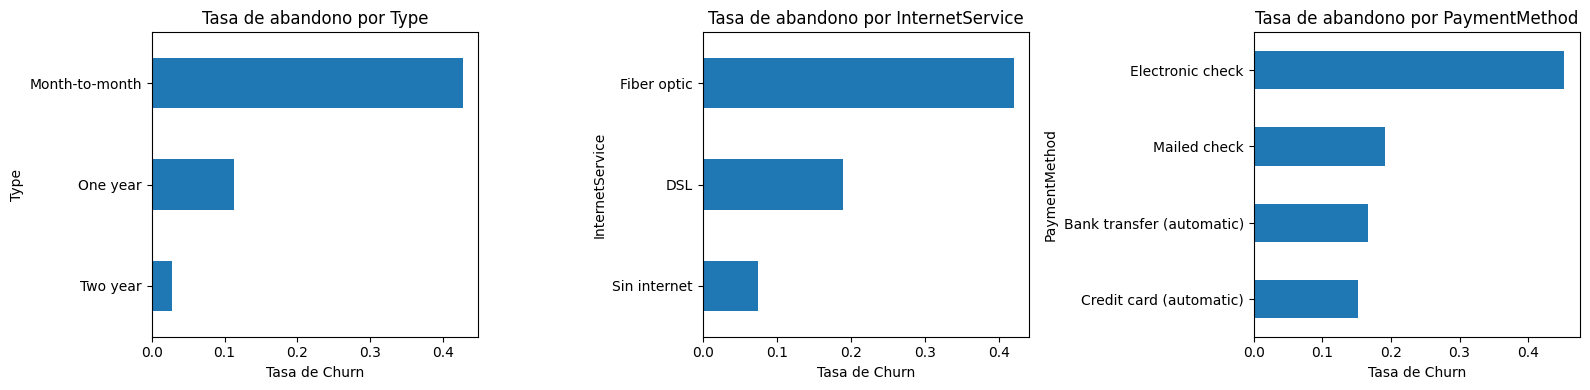

In [21]:
bfig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Type", "InternetService", "PaymentMethod"]):
    df.groupby(col)["Churn"].mean().sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Tasa de abandono por {col}")
    ax.set_xlabel("Tasa de Churn")
plt.tight_layout()
plt.show()

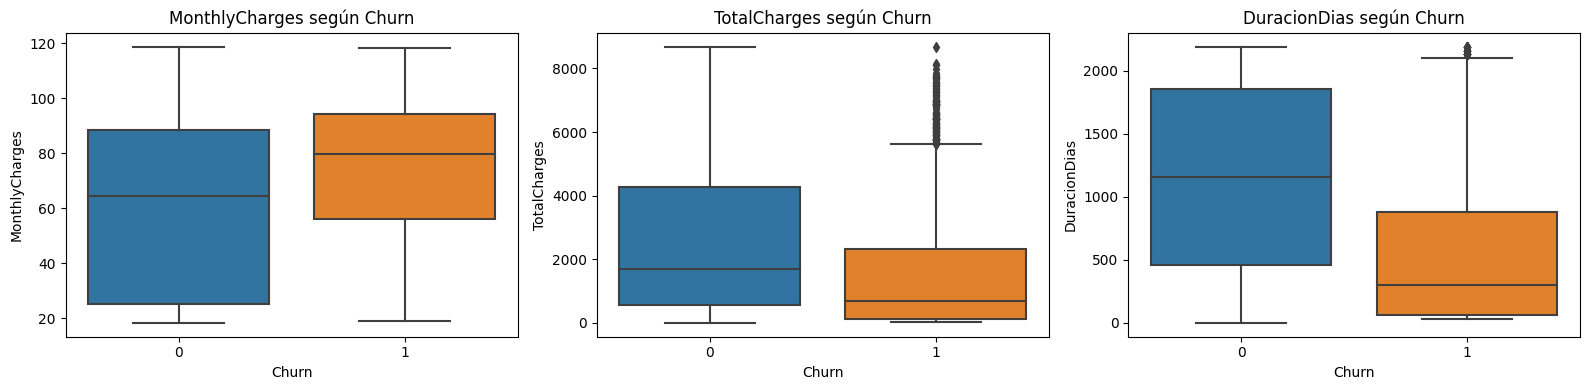

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["MonthlyCharges", "TotalCharges", "DuracionDias"]):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} según Churn")
plt.tight_layout()
plt.show()

**Lectura: tasa de abandono por categoría** (promedio global ≈ 26,5 %)

- **Contrato:** mes a mes **42,7 %**, un año 11,3 %, dos años **2,8 %**. Es la señal más fuerte.
- **Método de pago:** cheque electrónico **45,3 %** frente a ~15-19 % en el resto.
- **Internet:** fibra óptica **41,9 %** frente a 19,0 % en DSL.
- **Servicios de protección:** sin seguridad en línea o sin soporte técnico, ~42 % de abandono; con el servicio, ~15 %.
- **Perfil:** adultos mayores 41,7 % (vs 23,6 %); sin pareja 33,0 % y sin dependientes 31,3 %.
- **Señales débiles:** `gender` (26,9 % vs 26,2 %) no aporta; `StreamingTV`, `StreamingMovies` y `MultipleLines` difieren apenas 3-4 puntos.
- Los clientes **sin internet** abandonan 7,4 %. Son el mismo grupo de 1.526 clientes repetido en siete columnas, lo que implica colinealidad (se maneja con `drop="first"` en la regresión logística)

In [23]:
print(pd.crosstab(df["Type"], df["PaymentMethod"], normalize="index").round(2))
print(pd.crosstab(df["InternetService"], df["Type"], normalize="index").round(2))
print(df.groupby("InternetService")["MonthlyCharges"].mean().round(1))

PaymentMethod   Bank transfer (automatic)  Credit card (automatic)  \
Type                                                                 
Month-to-month                       0.15                     0.14   
One year                             0.27                     0.27   
Two year                             0.33                     0.34   

PaymentMethod   Electronic check  Mailed check  
Type                                            
Month-to-month              0.48          0.23  
One year                    0.24          0.23  
Two year                    0.10          0.23  
Type             Month-to-month  One year  Two year
InternetService                                    
DSL                        0.51      0.24      0.26
Fiber optic                0.69      0.17      0.14
Sin internet               0.34      0.24      0.42
InternetService
DSL             58.1
Fiber optic     91.5
Sin internet    21.1
Name: MonthlyCharges, dtype: float64


In [24]:
df.groupby("Churn")[["MonthlyCharges", "TotalCharges", "DuracionDias"]].median().round(1)

,MonthlyCharges,TotalCharges,DuracionDias
Churn,,,
0,64.4,1679.5,1157
1,79.6,703.6,304


**Lectura: variables numéricas y relaciones entre señales**

- Quienes se van pagan más al mes (mediana **79,6 vs 64,4**), tienen menos cargos acumulados (703,6 vs 1.679,5) y menos antigüedad (304 vs 1.157 días). Las dos últimas diferencias son en parte mecánicas: quien se va deja de acumular.
- Las señales están entrelazadas: el 48 % de los clientes mes a mes paga con cheque electrónico (10 % en contratos de dos años), el 69 % de los clientes con fibra está en mes a mes y la fibra cuesta 91,5 de promedio frente a 58,1 del DSL.
- **Conclusión del EDA:** el abandono se concentra en el perfil *contrato mes a mes + fibra óptica + cheque electrónico + sin soporte técnico ni seguridad en línea*. El mayor precio mensual probablemente refleja el tipo de servicio, no es necesariamente la causa del abandono (correlación no es causalidad).

#### Trazabilidad de las bajas

¿Cuándo se fueron los clientes y las cohortes de alta más recientes abandonan más? Se usa un filtro solo para este análisis; el DataFrame `df` completo queda intacto.

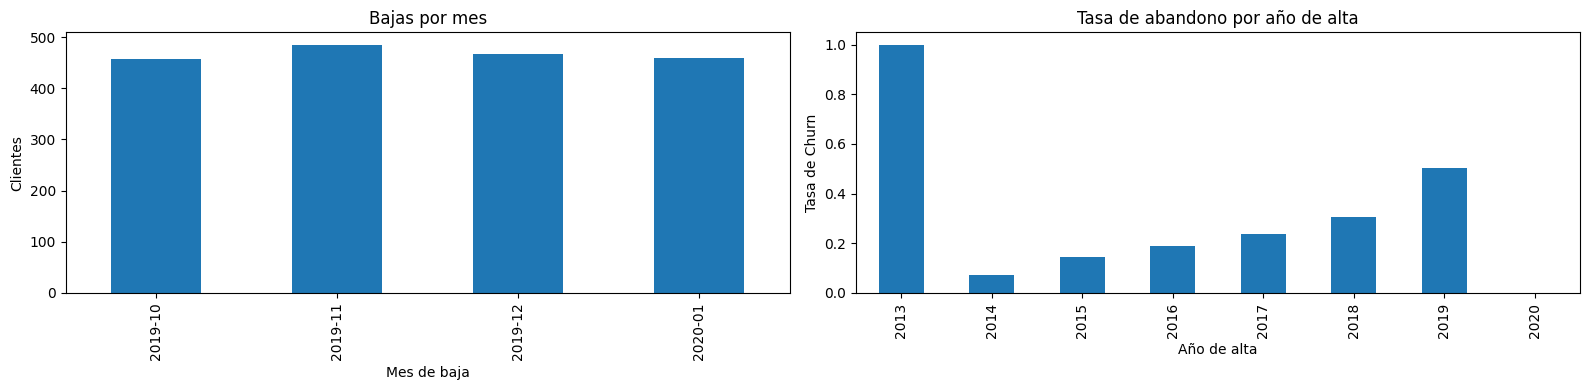

            mean  count
BeginDate              
2013       1.000      8
2014       0.073   1344
2015       0.144    852
2016       0.190    763
2017       0.236    845
2018       0.306   1030
2019       0.501   1957
2020       0.000    244


In [25]:
# Vista filtrada solo para este análisis (df completo no se modifica)
bajas = df[df["Churn"] == 1].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

bajas["EndDate"].dt.to_period("M").value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Bajas por mes")
axes[0].set_xlabel("Mes de baja")
axes[0].set_ylabel("Clientes")

cohortes = df.groupby(df["BeginDate"].dt.year)["Churn"].agg(["mean", "count"])
cohortes["mean"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Tasa de abandono por año de alta")
axes[1].set_xlabel("Año de alta")
axes[1].set_ylabel("Tasa de Churn")

plt.tight_layout()
plt.show()

print(cohortes.round(3))

### 3. Selección de Variables y Entrenamiento de Modelos (Baseline)

*Entrena al menos dos modelos distintos sin aplicar técnicas de balanceo de clases. Evalúa su AUC-ROC y Recall.*

El preprocesamiento se hace dentro de un `Pipeline` (escalado y codificación), de modo que se ajusta solo con los datos de entrenamiento y no hay fuga desde el conjunto de prueba. La partición es 80/20 **estratificada** para conservar el ~26,5 % de abandono en ambos conjuntos. En esta sección no se aplica ningún balanceo ni ajuste de umbral (umbral 0,5).

In [26]:

def preparar(usar_duracion):
    X = df.drop(columns=["customerID", "EndDate", "BeginDate", "Churn"])
    if not usar_duracion:
        X = X.drop(columns=["DuracionDias"])
    return X, df["Churn"]

def evaluar(usar_duracion):
    X, y = preparar(usar_duracion)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

    num = [c for c in ["MonthlyCharges", "TotalCharges", "DuracionDias"] if c in X.columns]
    cat = [c for c in X.columns if c not in num]

    modelos = {
        "LogisticRegression": Pipeline([
            ("prep", ColumnTransformer([("num", StandardScaler(), num),
                                        ("cat", OneHotEncoder(drop="first"), cat)])),
            ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        "RandomForest": Pipeline([
            ("prep", ColumnTransformer([("num", "passthrough", num),
                                        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
            ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]),
    }

    for nombre, m in modelos.items():
        m.fit(X_train, y_train)
        proba = m.predict_proba(X_test)[:, 1]
        pred = m.predict(X_test)
        print(f"{nombre:20s} AUC={roc_auc_score(y_test, proba):.3f}  Recall={recall_score(y_test, pred):.3f}")

print("CON DuracionDias"); evaluar(True)
print("\nSIN DuracionDias"); evaluar(False)

CON DuracionDias
LogisticRegression   AUC=0.837  Recall=0.570
RandomForest         AUC=0.834  Recall=0.513

SIN DuracionDias
LogisticRegression   AUC=0.831  Recall=0.537
RandomForest         AUC=0.808  Recall=0.463


**Lectura del baseline**
- Con regresión logística y Random Forest ya se supera el mínimo de aprobación (0,75) sin balanceo ni ajuste de hiperparámetros.
- El **Recall es bajo** (0,46-0,57): con umbral 0,5 y solo 26 % de abandono, los modelos tienden a predecir "se queda" y pierden a casi la mitad de quienes se van. Esto justifica la sección 4.
- Quitar `DuracionDias` baja el AUC 0,006 (regresión logística) y 0,026 (Random Forest).

### 4. Optimización y Manejo de Desbalance
*Aplica al menos una técnica para manejar el desbalance de clases (upsampling, downsampling, o ajuste de pesos) y busca los mejores hiperparámetros. Evalúa nuevamente.*


#### 4.1 Primer intento: LightGBM con pesos de clase, con `DuracionDias`

>  El AUC de **0,906** de esta búsqueda resultó **inflado por fuga de datos** (ver 4.2). Se muestra por transparencia, pero **no es el modelo final**.

Técnica de balanceo: `class_weight="balanced"`. Hiperparámetros: búsqueda aleatoria (40 combinaciones, validación cruzada estratificada de 5 folds, métrica AUC-ROC). El umbral se elige solo con probabilidades fuera de muestra del conjunto de entrenamiento.

In [27]:
X, y = preparar(True)   # primer intento CON DuracionDias (se contrasta en 4.2)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num = ["MonthlyCharges", "TotalCharges", "DuracionDias"]
cat = [c for c in X.columns if c not in num]

pipe = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", num),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
    ("clf", lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1))])

param_dist = {
    "clf__n_estimators": [200, 400, 600],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "clf__num_leaves": [8, 16, 31],
    "clf__max_depth": [3, 5, 7, -1],
    "clf__min_child_samples": [20, 40, 80],
    "clf__subsample": [0.7, 0.9, 1.0],
    "clf__colsample_bytree": [0.7, 0.9, 1.0],
    "clf__reg_lambda": [0, 1, 5],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
busqueda = RandomizedSearchCV(pipe, param_dist, n_iter=40, scoring="roc_auc",
                              cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Mejor AUC (CV):", round(busqueda.best_score_, 4))
print(busqueda.best_params_)

Mejor AUC (CV): 0.9064
{'clf__subsample': 1.0, 'clf__reg_lambda': 0, 'clf__num_leaves': 8, 'clf__n_estimators': 600, 'clf__min_child_samples': 20, 'clf__max_depth': 5, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.7}


In [28]:
mejor = busqueda.best_estimator_
proba_oof = cross_val_predict(mejor, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

umbrales = np.arange(0.2, 0.7, 0.05)
for t in umbrales:
    p = (proba_oof >= t).astype(int)
    print(f"umbral={t:.2f}  Recall={recall_score(y_train, p):.3f}  "
          f"Precision={precision_score(y_train, p):.3f}")

umbral=0.20  Recall=0.922  Precision=0.502
umbral=0.25  Recall=0.905  Precision=0.527
umbral=0.30  Recall=0.880  Precision=0.553
umbral=0.35  Recall=0.851  Precision=0.578
umbral=0.40  Recall=0.825  Precision=0.601
umbral=0.45  Recall=0.797  Precision=0.634
umbral=0.50  Recall=0.778  Precision=0.665
umbral=0.55  Recall=0.750  Precision=0.696
umbral=0.60  Recall=0.714  Precision=0.721
umbral=0.65  Recall=0.680  Precision=0.756


In [29]:
UMBRAL = 0.40   # reemplaza por el que elijas
proba_test = mejor.fit(X_train, y_train).predict_proba(X_test)[:, 1]
pred_test = (proba_test >= UMBRAL).astype(int)
print(f"AUC test={roc_auc_score(y_test, proba_test):.3f}  "
      f"Recall={recall_score(y_test, pred_test):.3f}  "
      f"Precision={precision_score(y_test, pred_test):.3f}")

AUC test=0.906  Recall=0.837  Precision=0.597


#### 4.2 Detección de fuga de datos

`DuracionDias` usa la fecha de baja en quienes se fueron, y `TotalCharges` arrastra parte de esa misma información (cargos acumulados hasta la baja). Se repite la búsqueda quitando estas variables:

| Variables excluidas | AUC CV | AUC test | Recall |
|---|---|---|---|
| Ninguna | 0,906 | 0,906 | 0,837 |
| `DuracionDias` | 0,850 | 0,843 | 0,872 |
| `DuracionDias` + `TotalCharges` | 0,829 | 0,825 | 0,874 |

El AUC cae 0,06 al quitar `DuracionDias`: **había fuga**. Se adopta como modelo final la versión **sin `DuracionDias`** (AUC 0,843), que es la cifra que se puede esperar en producción. Incluso la versión más estricta (0,825) sigue aprobando.

In [30]:

def correr(columnas_a_quitar, n_iter=40, con_dias_desde_alta=False):
    X, y = preparar(True)
    X = X.drop(columns=columnas_a_quitar)
    if con_dias_desde_alta:
        # Antigüedad medida hasta la fecha de corte común: no depende de la fecha de baja
        X["DiasDesdeAlta"] = (df["BeginDate"].max() - df["BeginDate"]).dt.days
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    num = [c for c in ["MonthlyCharges", "TotalCharges", "DuracionDias", "DiasDesdeAlta"] if c in X.columns]
    cat = [c for c in X.columns if c not in num]
    pipe = Pipeline([
        ("prep", ColumnTransformer([("num", "passthrough", num),
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
        ("clf", lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1))])
    b = RandomizedSearchCV(pipe, param_dist, n_iter=n_iter, scoring="roc_auc",
                           cv=cv, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    proba = b.best_estimator_.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.40).astype(int)
    extra = " + DiasDesdeAlta" if con_dias_desde_alta else ""
    print(f"quitando {columnas_a_quitar or 'nada'}{extra}: "
          f"AUC CV={b.best_score_:.3f}  AUC test={roc_auc_score(y_test, proba):.3f}  "
          f"Recall={recall_score(y_test, pred):.3f}")

correr([])                                   # con todas las variables
correr(["DuracionDias"])                     # sin duración
correr(["DuracionDias", "TotalCharges"])     # sin duración ni acumulado

quitando nada: AUC CV=0.906  AUC test=0.906  Recall=0.837
quitando ['DuracionDias']: AUC CV=0.850  AUC test=0.843  Recall=0.872
quitando ['DuracionDias', 'TotalCharges']: AUC CV=0.829  AUC test=0.825  Recall=0.874


**Prueba adicional sin fuga:** `DiasDesdeAlta` mide la antigüedad hasta la fecha de corte común (2020-02-01), igual para todos los clientes, por lo que no depende de la fecha de baja. Se prueba como reemplazo de la duración, sin `DuracionDias` ni `TotalCharges`. Compara su AUC con las filas anteriores.


In [31]:
correr(["DuracionDias", "TotalCharges"], con_dias_desde_alta=True)

quitando ['DuracionDias', 'TotalCharges'] + DiasDesdeAlta: AUC CV=0.858  AUC test=0.856  Recall=0.880


In [32]:
# Modelo final: sin DuracionDias
X, y = preparar(False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num = ["MonthlyCharges", "TotalCharges"]
cat = [c for c in X.columns if c not in num]

pipe = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", num),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
    ("clf", lgb.LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, verbose=-1))])

busqueda = RandomizedSearchCV(pipe, param_dist, n_iter=40, scoring="roc_auc",
                              cv=cv, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
final = busqueda.best_estimator_
print("AUC CV:", round(busqueda.best_score_, 3), busqueda.best_params_)

# Umbral elegido solo con entrenamiento (probabilidades fuera de muestra)
proba_oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
for t in np.arange(0.20, 0.70, 0.05):
    p = (proba_oof >= t).astype(int)
    print(f"umbral={t:.2f}  Recall={recall_score(y_train, p):.3f}  Precision={precision_score(y_train, p):.3f}")

AUC CV: 0.85 {'clf__subsample': 0.7, 'clf__reg_lambda': 5, 'clf__num_leaves': 16, 'clf__n_estimators': 600, 'clf__min_child_samples': 80, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__colsample_bytree': 0.7}
umbral=0.20  Recall=0.958  Precision=0.388
umbral=0.25  Recall=0.942  Precision=0.408
umbral=0.30  Recall=0.926  Precision=0.432
umbral=0.35  Recall=0.908  Precision=0.451
umbral=0.40  Recall=0.882  Precision=0.472
umbral=0.45  Recall=0.853  Precision=0.494
umbral=0.50  Recall=0.810  Precision=0.522
umbral=0.55  Recall=0.759  Precision=0.546
umbral=0.60  Recall=0.690  Precision=0.584
umbral=0.65  Recall=0.631  Precision=0.615


In [33]:
UMBRAL = 0.40   # ajústalo según la tabla anterior
proba_test = final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= UMBRAL).astype(int)
print(f"AUC test={roc_auc_score(y_test, proba_test):.3f}  "
      f"Recall={recall_score(y_test, pred_test):.3f}  "
      f"Precision={precision_score(y_test, pred_test):.3f}")

AUC test=0.843  Recall=0.872  Precision=0.450


#### 4.4 Comparación de modelos y diagnóstico del modelo final

Todas las métricas son sobre el conjunto de prueba. Los baselines usan umbral 0,5 y los LightGBM umbral 0,40 con pesos de clase, así que parte de la mejora de Recall viene del umbral y del balanceo, no solo del algoritmo.

| Modelo | Variables | Balanceo / umbral | AUC-ROC | Recall |
|---|---|---|---|---|
| Regresión logística | con `DuracionDias` | ninguno / 0,5 | 0,837 | 0,570 |
| Random Forest | con `DuracionDias` | ninguno / 0,5 | 0,834 | 0,513 |
| Regresión logística | sin `DuracionDias` | ninguno / 0,5 | 0,831 | 0,537 |
| Random Forest | sin `DuracionDias` | ninguno / 0,5 | 0,808 | 0,463 |
| LightGBM (descartado, fuga) | con `DuracionDias` | pesos / 0,40 | 0,906 | 0,837 |
| LightGBM | sin `DuracionDias` ni `TotalCharges` | pesos / 0,40 | 0,825 | 0,874 |
| **LightGBM (final)** | **sin `DuracionDias`** | **pesos / 0,40** | **0,843** | **0,872** |

In [34]:
# Impacto de negocio sobre el conjunto de prueba
yt = y_test.values
n_test = len(yt)
n_churn = int(yt.sum())
tp = int(((pred_test == 1) & (yt == 1)).sum())
fp = int(((pred_test == 1) & (yt == 0)).sum())
fn = int(((pred_test == 0) & (yt == 1)).sum())
tn = int(((pred_test == 0) & (yt == 0)).sum())

print(f"Clientes en test: {n_test} | que se van: {n_churn} ({n_churn/n_test:.1%})")
print(f"Detectados (TP): {tp} | No detectados (FN): {fn} | Falsas alarmas (FP): {fp} | Correctos que se quedan (TN): {tn}")
print(f"Clientes marcados como riesgo: {tp+fp} ({(tp+fp)/n_test:.0%} de la base)")
print(f"Tasa de abandono entre marcados: {tp/(tp+fp):.1%} vs {n_churn/n_test:.1%} en la base "
      f"({(tp/(tp+fp))/(n_churn/n_test):.1f} veces más)")

Clientes en test: 1409 | que se van: 374 (26.5%)
Detectados (TP): 326 | No detectados (FN): 48 | Falsas alarmas (FP): 398 | Correctos que se quedan (TN): 637
Clientes marcados como riesgo: 724 (51% de la base)
Tasa de abandono entre marcados: 45.0% vs 26.5% en la base (1.7 veces más)


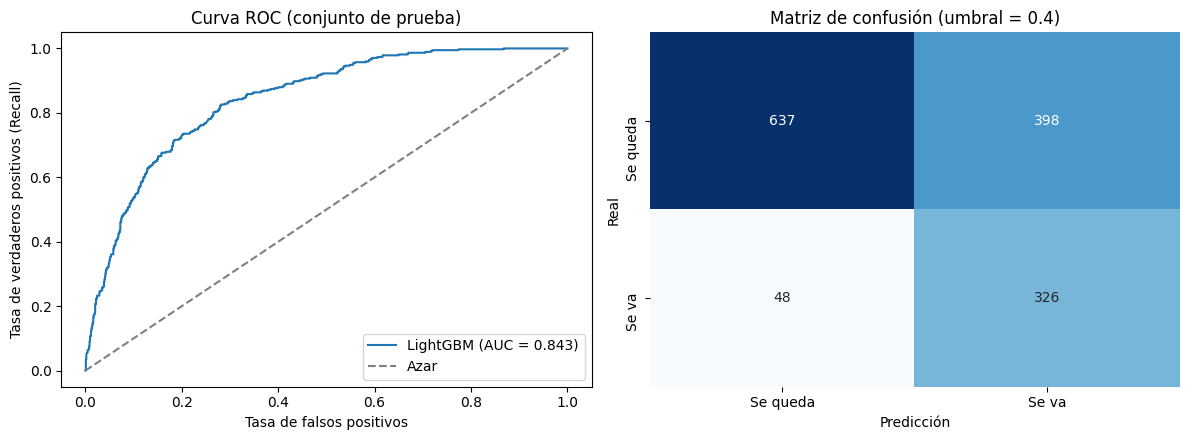

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[0].plot(fpr, tpr, label=f"LightGBM (AUC = {roc_auc_score(y_test, proba_test):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[0].set_title("Curva ROC (conjunto de prueba)")
axes[0].legend(loc="lower right")

# Matriz de confusión
sns.heatmap(confusion_matrix(y_test, pred_test), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Se queda", "Se va"], yticklabels=["Se queda", "Se va"], ax=axes[1])
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Real")
axes[1].set_title(f"Matriz de confusión (umbral = {UMBRAL})")

plt.tight_layout()
plt.show()

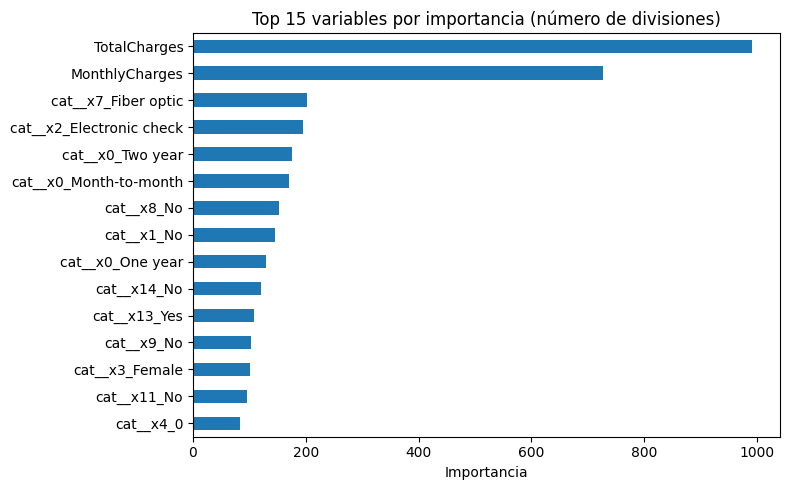

In [36]:
# Importancia de variables del LightGBM final
prep = final.named_steps["prep"]
try:
    nombres = prep.get_feature_names_out()
except AttributeError:               # versiones antiguas de scikit-learn
    nombres = prep.get_feature_names()

imp = pd.Series(final.named_steps["clf"].feature_importances_, index=nombres)
imp = imp.sort_values(ascending=False).head(15)

imp.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 15 variables por importancia (número de divisiones)")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

## Etapa 3: Informe de Solución

*Para el equipo de marketing de Interconnect. Las cifras de impacto son aproximadas y salen de la celda "Impacto de negocio" (conjunto de prueba de 1.409 clientes).*

### 1. ¿Qué modelo elegimos y por qué?

**LightGBM** con pesos de clase balanceados, hiperparámetros optimizados con validación cruzada de 5 folds y un umbral de decisión de 0,40, entrenado **sin la variable de duración del contrato**.

- Es el mejor modelo entre los que no usan información del futuro: supera a la regresión logística (AUC 0,831) y al Random Forest (0,808) del baseline, y tiene un Recall mucho mayor.
- Una versión con la duración llegó a AUC 0,906, pero esa cifra estaba **inflada**: para quienes se van, la duración se calcula hasta su fecha de baja, información que marketing no tendría antes de que el cliente se vaya. La descartamos para que el resultado sea el que realmente se obtendría en producción.

### 2. Métricas finales en el conjunto de prueba

| Métrica | Valor |
|---|---|
| **AUC-ROC** | **0,843** (categoría "Bueno": 0,81 a 0,85; el mínimo de aprobación es 0,75) |
| **Recall** | **0,872** |
| Precision | 0,450 |

El umbral (0,40) se eligió solo con datos de entrenamiento, no con el conjunto de prueba.

### 3. Qué significa en términos de negocio

- **Recall 0,872:** de cada 100 clientes que se irían, el modelo identifica a unos **87**. Solo ~13 se van sin que marketing los haya contactado. En el conjunto de prueba, de unos 374 clientes que se van, el modelo detecta ~326 y pierde ~48.
- **Costo de esa cobertura (Precision 0,45):** el modelo marca a ~725 clientes (~51 % de la base) y 45 de cada 100 marcados realmente se iban, es decir, ~1,7 veces la tasa de abandono general (26,5 %). Los otros ~55 recibirían una promoción que no necesitaban.
- **Si marketing lo usa hoy:** puede concentrar las ofertas en la mitad de la base en lugar de ofrecerlas a todos, alcanzando a casi 9 de cada 10 clientes en riesgo. Conviene cuando la promoción cuesta menos que el ingreso de un cliente que se pierde; si la oferta es muy cara, se puede subir el umbral (más precisión, menos Recall).

**Perfil de mayor riesgo:** contrato mes a mes, fibra óptica, pago con cheque electrónico, sin soporte técnico ni seguridad en línea, y adultos mayores. Los contratos de uno o dos años y los pagos automáticos se asocian a mucha menor fuga; son candidatos para ofertas de migración (esto es una asociación, no una causa demostrada).
